# prepare dataset

In [ ]:
!pip install kaggle

In [1]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"saraa1z","key":"dd3e4cb2fe11bc403bcd5da736d17f5c"}'}

In [2]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [3]:
!kaggle datasets download -d hsankesara/flickr-image-dataset

100% 8.15G/8.16G [01:48<00:00, 95.8MB/s]
100% 8.16G/8.16G [01:48<00:00, 81.0MB/s]


In [4]:
!ls

flickr-image-dataset.zip  kaggle.json  sample_data


In [ ]:
import zipfile
zip_ref = zipfile.ZipFile('flickr-image-dataset.zip', 'r')
zip_ref.extractall('files')
zip_ref.close()

In [ ]:
!ls

files  flickr-image-dataset.zip  kaggle.json  sample_data


## load dataset

In [ ]:
!python -m spacy download en_core_web_sm

2024-01-30 13:42:44.256740: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-01-30 13:42:44.256816: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-01-30 13:42:44.259083: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-01-30 13:42:46.159696: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 36.0 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [ ]:
import tensorflow as tf
import cv2
import numpy as np
import os
from matplotlib import pyplot as plt
import random

In [ ]:
train_images_list = os.listdir("/content/files/flickr30k_images/flickr30k_images")

In [ ]:
sample_size = 30
train_images_list = train_images_list[:sample_size]

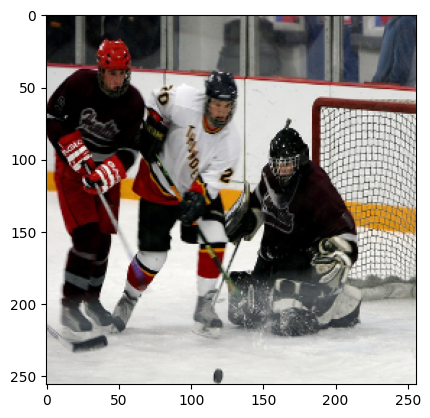

In [ ]:
size = (256, 256)
num_channels = 3

train = np.array([None] * sample_size)
real_images = np.array([None] * sample_size)

j = 0
for i in train_images_list:
    real_images[j] = np.array(plt.imread("/content/files/flickr30k_images/flickr30k_images/" + i))
    train[j] = np.array(plt.imread("/content/files/flickr30k_images/flickr30k_images/"+ i))
    j += 1

j = 0
for i in train:
    train[j] = cv2.resize(i, size)
    train[j] = train[j].reshape(1, size[0], size[1], num_channels)
    j += 1

train = np.vstack(train[:])

plt.imshow(np.squeeze(train[0]))
plt.show()



In [ ]:
import pandas as pd
import re

train_captions = pd.read_csv('/content/files/flickr30k_images/results.csv', delimiter='|')

def get_images_id(names):
    names = [int(x.split('_')[-1].split('.')[0]) for x in names]
    return names

# ids = get_images_id(train_images_list[:sample_size])

train_captions.columns = ['image_name', 'comment_number', 'comment']

def images_map_caption(train_images_list, train_captions):
    caption = []
    for i in train_images_list:
        caption.append(train_captions[train_captions['image_name'] == i]['comment'].iat[0])
    return caption

captions = np.array(images_map_caption(train_images_list, train_captions))
print(captions.shape)

(30,)


In [ ]:
start_tag = '<s>'
end_tag = '<e>'

def get_vocab(captions):
    arr = []
    m = captions.shape[0]
    sentence = [None ] * m
    j  = 0
    for i in captions:
        i = re.sub(' +',' ',i)
        i = start_tag + ' ' + i + ' ' + end_tag
        sentence[j] = i.split()
        j += 1
        arr = arr + i.split()
    arr = list(set(arr))
    vocab_size = len(arr)
    j = 0
    fwd_dict = {}
    rev_dict = {}
    j = 0
    for i in arr:
        fwd_dict[i] = j
        rev_dict[j] = i
        j += 1
    return vocab_size, sentence, fwd_dict, rev_dict

vocab_size, sentences, fwd_dict, rev_dict = get_vocab(captions)

from scipy.sparse import csr_matrix
from scipy.sparse import vstack

m = len(sentences)
train_caption = [None] * m
i = 0
for sentence in sentences:
    cap_array = None
    for word in sentence:
        row = [0]
        col = [fwd_dict[word]]
        data = [1]
        if cap_array is None:
            cap_array = csr_matrix((data, (row, col)), shape=(1, vocab_size))
        else:
            cap_array = vstack((cap_array, csr_matrix((data, (row, col)), shape=(1, vocab_size))))
    train_caption[i] = cap_array
    i += 1

train_caption[0].shape

(23, 247)

In [ ]:
train_caption[1]

<18x247 sparse matrix of type '<class 'numpy.int64'>'
	with 18 stored elements in Compressed Sparse Row format>

# model

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

def create_weights(shape, suffix):
    return nn.Parameter(torch.randn(shape) * 0.7, requires_grad=True)

def create_biases(size, suffix):
    return nn.Parameter(torch.zeros(size), requires_grad=True)

class ConvLayer(nn.Module):
    def __init__(self, num_channels, num_kernels, suffix):
        super(ConvLayer, self).__init__()
        self.weights = create_weights((num_kernels, num_channels, 3, 3), suffix)
        self.biases = create_biases(num_kernels, suffix)

    def forward(self, inp):
        layer = F.conv2d(inp, self.weights, padding=1)
        layer += self.biases.unsqueeze(0).unsqueeze(-1).unsqueeze(-1)
        layer = F.relu6(layer)
        return layer

class FlattenLayer(nn.Module):
    def forward(self, layer):
        return layer.view(layer.size(0), -1)

class DenseLayer(nn.Module):
    def __init__(self, num_inputs, num_outputs, suffix):
        super(DenseLayer, self).__init__()
        self.weights = create_weights((num_inputs, num_outputs), suffix)
        self.biases = create_biases(num_outputs, suffix)

    def forward(self, inp):
        layer = torch.matmul(inp, self.weights) + self.biases
        layer = F.relu(layer)
        return layer

def rnn_cell(Win, Wout, Wfwd, b, hprev, inp):
    h = torch.tanh(torch.matmul(inp, Win) + torch.matmul(hprev, Wfwd) + b)
    out = torch.matmul(h, Wout)
    return h, out

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

learning_rate = 0.0001
training_iters = 5000
display_step = 1000
max_sent_limit = 50
num_tests = 12
bridge_size = 1024
keep_prob = 0.3

# Assuming vocab_size, size, num_channels are defined elsewhere

x_caption = torch.tensor(np.zeros((1, vocab_size)), dtype=torch.float32)
x_inp = torch.tensor(np.zeros((1, size[0], size[1], num_channels)), dtype=torch.float32)
y = torch.tensor(np.zeros((1, vocab_size)), dtype=torch.float32)

Wconv = create_weights((bridge_size, vocab_size), "")
bconv = create_biases((1, vocab_size), "")
Wi = create_weights((vocab_size, vocab_size), "")
Wf = create_weights((vocab_size, vocab_size), "")
Wo = create_weights((vocab_size, vocab_size), "")
b = create_biases((1, vocab_size), "")

layer_conv1 = ConvLayer(num_channels=3, num_kernels=32, suffix='1')
layer_conv2 = ConvLayer(num_channels=32, num_kernels=32, suffix='2')
maxpool1 = nn.MaxPool2d(2, 2)
layer_conv3 = ConvLayer(num_channels=32, num_kernels=64, suffix='3')
layer_conv4 = ConvLayer(num_channels=64, num_kernels=64, suffix='4')
maxpool2 = nn.MaxPool2d(2, 2)
layer_conv5 = ConvLayer(num_channels=64, num_kernels=128, suffix='5')
layer_conv6 = ConvLayer(num_channels=128, num_kernels=128, suffix='6')
maxpool3 = nn.MaxPool2d(2, 2)
layer_conv7 = ConvLayer(num_channels=128, num_kernels=256, suffix='7')
layer_conv8 = ConvLayer(num_channels=256, num_kernels=256, suffix='8')

flatten_layer = FlattenLayer()

dense_layer_1 = DenseLayer(num_inputs=247, num_outputs=bridge_size, suffix='10')

start_hook = torch.sparse.FloatTensor(torch.LongTensor([[0], [fwd_dict[start_tag]]]), torch.FloatTensor([1]), torch.Size([1, vocab_size])).to(device)
end_hook = torch.sparse.FloatTensor(torch.LongTensor([[0], [fwd_dict[end_tag]]]), torch.FloatTensor([1]), torch.Size([1, vocab_size])).to(device)

hook = x_caption[0:1]
h = dense_layer_1(hook)
_, output = rnn_cell(Wi, Wo, Wconv, bconv, h, hook)

def fn(prev, curr):
    h = prev[0]
    h, out = rnn_cell(Wi, Wo, Wf, b, h, curr.unsqueeze(0))
    return h, out

h = torch.zeros(1, bridge_size).to(device)
_, output = torch.jit.script(torch.scan(fn, x_caption[1:], (h, output))[1])

output = torch.squeeze(output, dim=1)

outputs = torch.cat([output, output], dim=0)

cost = F.cross_entropy(outputs, torch.argmax(y, 1))
optimizer = torch.optim.Adam(cost.parameters(), lr=learning_rate)

pred = F.softmax(outputs, dim=1)

# Model evaluation
correct_pred = torch.eq(torch.argmax(pred, 1), torch.argmax(y, 1))
accuracy = torch.mean(correct_pred.float())


<ipython-input-29-08819fc28d04>:83: UserWarning: torch.sparse.SparseTensor(indices, values, shape, *, device=) is deprecated.  Please use torch.sparse_coo_tensor(indices, values, shape, dtype=, device=). (Triggered internally at ../torch/csrc/utils/tensor_new.cpp:605.)
  start_hook = torch.sparse.FloatTensor(torch.LongTensor([[0], [fwd_dict[start_tag]]]), torch.FloatTensor([1]), torch.Size([1, vocab_size])).to(device)


RuntimeError: mat1 and mat2 shapes cannot be multiplied (1x247 and 262144x1024)

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

def create_weights(shape, suffix):
    return nn.Parameter(torch.randn(shape) * 0.7, requires_grad=True)

def create_biases(size, suffix):
    return nn.Parameter(torch.zeros(size), requires_grad=True)

class ConvLayer(nn.Module):
    def __init__(self, num_channels, num_kernels, suffix):
        super(ConvLayer, self).__init__()
        self.weights = create_weights((num_kernels, num_channels, 3, 3), suffix)
        self.biases = create_biases(num_kernels, suffix)

    def forward(self, inp):
        layer = F.conv2d(inp, self.weights, padding=1)
        layer += self.biases.unsqueeze(0).unsqueeze(-1).unsqueeze(-1)
        layer = F.relu6(layer)
        return layer

def flatten_layer(layer, suffix):
    return layer.view(layer.size(0), -1)

class DenseLayer(nn.Module):
    def __init__(self, num_inputs, num_outputs, suffix):
        super(DenseLayer, self).__init__()
        self.weights = create_weights((num_inputs, num_outputs), suffix)
        self.biases = create_biases(num_outputs, suffix)

    def forward(self, inp):
        layer = torch.matmul(inp, self.weights) + self.biases
        layer = F.relu(layer)
        return layer

def rnn_cell(Win, Wout, Wfwd, b, hprev, inp):
    h = torch.tanh(torch.matmul(inp, Win) + torch.matmul(hprev, Wfwd) + b)
    out = torch.matmul(h, Wout)
    return h, out

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

learning_rate = 0.0001
training_iters = 5000
display_step = 1000
max_sent_limit = 50
num_tests = 12
bridge_size = 1024
keep_prob = 0.3

# Assuming vocab_size, size, num_channels are defined elsewhere

x_caption = torch.tensor(np.zeros((1, vocab_size)), dtype=torch.float32)
x_inp = torch.tensor(np.zeros((1, size[0], size[1], num_channels)), dtype=torch.float32)
y = torch.tensor(np.zeros((1, vocab_size)), dtype=torch.float32)

Wconv = create_weights((bridge_size, vocab_size), "")
bconv = create_biases((1, vocab_size), "")
Wi = create_weights((vocab_size, vocab_size), "")
Wf = create_weights((vocab_size, vocab_size), "")
Wo = create_weights((vocab_size, vocab_size), "")
b = create_biases((1, vocab_size), "")

layer_conv1 = ConvLayer(num_channels=3, num_kernels=32, suffix='1')
layer_conv2 = ConvLayer(num_channels=32, num_kernels=32, suffix='2')
maxpool1 = nn.MaxPool2d(2, 2)
layer_conv3 = ConvLayer(num_channels=32, num_kernels=64, suffix='3')
layer_conv4 = ConvLayer(num_channels=64, num_kernels=64, suffix='4')
maxpool2 = nn.MaxPool2d(2, 2)
layer_conv5 = ConvLayer(num_channels=64, num_kernels=128, suffix='5')
layer_conv6 = ConvLayer(num_channels=128, num_kernels=128, suffix='6')
maxpool3 = nn.MaxPool2d(2, 2)
layer_conv7 = ConvLayer(num_channels=128, num_kernels=256, suffix='7')
layer_conv8 = ConvLayer(num_channels=256, num_kernels=256, suffix='8')

flat_layer = flatten_layer(layer_conv8, suffix='9')
dense_layer_1 = DenseLayer(num_inputs=262144, num_outputs=bridge_size, suffix='10')

start_hook = torch.sparse.FloatTensor(torch.LongTensor([[0], [fwd_dict[start_tag]]]), torch.FloatTensor([1]), torch.Size([1, vocab_size])).to(device)
end_hook = torch.sparse.FloatTensor(torch.LongTensor([[0], [fwd_dict[end_tag]]]), torch.FloatTensor([1]), torch.Size([1, vocab_size])).to(device)

hook = x_caption[0:1]
h = dense_layer_1(hook)
_, output = rnn_cell(Wi, Wo, Wconv, bconv, h, hook)

def fn(prev, curr):
    h = prev[0]
    h, out = rnn_cell(Wi, Wo, Wf, b, h, curr.unsqueeze(0))
    return h, out

h = torch.zeros(1, bridge_size).to(device)
_, output = torch.jit.script(torch.scan(fn, x_caption[1:], (h, output))[1])

output = torch.squeeze(output, dim=1)

outputs = torch.cat([output, output], dim=0)

cost = F.cross_entropy(outputs, torch.argmax(y, 1))
optimizer = torch.optim.Adam(cost.parameters(), lr=learning_rate)

pred = F.softmax(outputs, dim=1)

# Model evaluation
correct_pred = torch.eq(torch.argmax(pred, 1), torch.argmax(y, 1))
accuracy = torch.mean(correct_pred.float())


AttributeError: 'ConvLayer' object has no attribute 'view'

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

def create_weights(shape, suffix):
    return nn.Parameter(torch.randn(shape) * 0.7, requires_grad=True)

def create_biases(size, suffix):
    return nn.Parameter(torch.zeros(size), requires_grad=True)

class ConvLayer(nn.Module):
    def __init__(self, num_channels, num_kernels, suffix):
        super(ConvLayer, self).__init__()
        self.weights = create_weights((num_kernels, num_channels, 3, 3), suffix)
        self.biases = create_biases(num_kernels, suffix)

    def forward(self, inp):
        layer = F.conv2d(inp, self.weights, padding=1)
        layer += self.biases.unsqueeze(0).unsqueeze(-1).unsqueeze(-1)
        layer = F.relu6(layer)
        return layer

def flatten_layer(layer, suffix):
    return layer.view(layer.size(0), -1)

class DenseLayer(nn.Module):
    def __init__(self, num_inputs, num_outputs, suffix):
        super(DenseLayer, self).__init__()
        self.weights = create_weights((num_inputs, num_outputs), suffix)
        self.biases = create_biases(num_outputs, suffix)

    def forward(self, inp):
        layer = torch.matmul(inp, self.weights) + self.biases
        layer = F.relu(layer)
        return layer

def rnn_cell(Win, Wout, Wfwd, b, hprev, inp):
    h = torch.tanh(torch.matmul(inp, Win) + torch.matmul(hprev, Wfwd) + b)
    out = torch.matmul(h, Wout)
    return h, out

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

learning_rate = 0.0001
training_iters = 5000
display_step = 1000
max_sent_limit = 50
num_tests = 12
bridge_size = 1024
keep_prob = 0.3

x_caption = torch.placeholder(torch.float32, [None, vocab_size], name='x_caption')
x_inp = torch.placeholder(torch.float32, [1, size[0], size[1], num_channels], name='x_image')
y = torch.placeholder(torch.float32, [None, vocab_size], name='x_caption')

Wconv = create_weights((bridge_size, vocab_size), "")
bconv = create_biases((1, vocab_size), "")
Wi = create_weights((vocab_size, vocab_size), "")
Wf = create_weights((vocab_size, vocab_size), "")
Wo = create_weights((vocab_size, vocab_size), "")
b = create_biases((1, vocab_size), "")

layer_conv1 = ConvLayer(num_channels=3, num_kernels=32, suffix='1')
layer_conv2 = ConvLayer(num_channels=32, num_kernels=32, suffix='2')
maxpool1 = nn.MaxPool2d(2, 2)
layer_conv3 = ConvLayer(num_channels=32, num_kernels=64, suffix='3')
layer_conv4 = ConvLayer(num_channels=64, num_kernels=64, suffix='4')
maxpool2 = nn.MaxPool2d(2, 2)
layer_conv5 = ConvLayer(num_channels=64, num_kernels=128, suffix='5')
layer_conv6 = ConvLayer(num_channels=128, num_kernels=128, suffix='6')
maxpool3 = nn.MaxPool2d(2, 2)
layer_conv7 = ConvLayer(num_channels=128, num_kernels=256, suffix='7')
layer_conv8 = ConvLayer(num_channels=256, num_kernels=256, suffix='8')

flat_layer = flatten_layer(layer_conv8, suffix='9')
dense_layer_1 = DenseLayer(num_inputs=262144, num_outputs=bridge_size, suffix='10')

start_hook = torch.sparse.FloatTensor(torch.LongTensor([[0], [fwd_dict[start_tag]]]), torch.FloatTensor([1]), torch.Size([1, vocab_size])).to(device)
end_hook = torch.sparse.FloatTensor(torch.LongTensor([[0], [fwd_dict[end_tag]]]), torch.FloatTensor([1]), torch.Size([1, vocab_size])).to(device)

hook = x_caption[0:1]
h = dense_layer_1(hook)
_, output = rnn_cell(Wi, Wo, Wconv, bconv, h, hook)

def fn(prev, curr):
    h = prev[0]
    h, out = rnn_cell(Wi, Wo, Wf, b, h, curr.unsqueeze(0))
    return h, out

h = torch.zeros(1, bridge_size).to(device)
_, output = torch.jit.script(torch.scan(fn, x_caption[1:], (h, output))[1])

output = torch.squeeze(output, dim=1)

outputs = torch.cat([output, output], dim=0)

cost = F.cross_entropy(outputs, torch.argmax(y, 1))
optimizer = torch.optim.Adam(cost.parameters(), lr=learning_rate)

pred = F.softmax(outputs, dim=1)

# Model evaluation
correct_pred = torch.eq(torch.argmax(pred, 1), torch.argmax(y, 1))
accuracy = torch.mean(correct_pred.float())


AttributeError: module 'torch' has no attribute 'placeholder'

In [ ]:
import os  # when loading file paths
import pandas as pd  # for lookup in annotation file
import spacy  # for tokenizer
import torch
from torch.nn.utils.rnn import pad_sequence  # pad batch
from torch.utils.data import DataLoader, Dataset
from PIL import Image  # Load img
import torchvision.transforms as transforms


spacy_eng = spacy.load("en_core_web_sm")


class Vocabulary:
    def __init__(self, freq_threshold):
        self.itos = {0: "<PAD>", 1: "<SOS>", 2: "<EOS>", 3: "<UNK>"}
        self.stoi = {"<PAD>": 0, "<SOS>": 1, "<EOS>": 2, "<UNK>": 3}
        self.freq_threshold = freq_threshold

    def __len__(self):
        return len(self.itos)

    @staticmethod
    def tokenizer_eng(text):
        return [tok.text.lower() for tok in spacy_eng.tokenizer(text)]

    def build_vocabulary(self, sentence_list):
        frequencies = {}
        idx = 4

        for sentence in sentence_list:
            for word in self.tokenizer_eng(sentence):
                if word not in frequencies:
                    frequencies[word] = 1

                else:
                    frequencies[word] += 1

                if frequencies[word] == self.freq_threshold:
                    self.stoi[word] = idx
                    self.itos[idx] = word
                    idx += 1

    def numericalize(self, text):
        tokenized_text = self.tokenizer_eng(text)

        return [
            self.stoi[token] if token in self.stoi else self.stoi["<UNK>"]
            for token in tokenized_text
        ]


class FlickrDataset(Dataset):
    def __init__(self, root_dir, captions_file, transform=None, freq_threshold=5):
        self.root_dir = root_dir
        self.df = pd.read_csv(captions_file)
        self.transform = transform

        # Get img, caption columns
        self.imgs = self.df["image"]
        self.captions = self.df["caption"]

        # Initialize vocabulary and build vocab
        self.vocab = Vocabulary(freq_threshold)
        self.vocab.build_vocabulary(self.captions.tolist())

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        caption = self.captions[index]
        img_id = self.imgs[index]
        img = Image.open(os.path.join(self.root_dir, img_id)).convert("RGB")

        if self.transform is not None:
            img = self.transform(img)

        numericalized_caption = [self.vocab.stoi["<SOS>"]]
        numericalized_caption += self.vocab.numericalize(caption)
        numericalized_caption.append(self.vocab.stoi["<EOS>"])

        return img, torch.tensor(numericalized_caption)


class MyCollate:
    def __init__(self, pad_idx):
        self.pad_idx = pad_idx

    def __call__(self, batch):
        imgs = [item[0].unsqueeze(0) for item in batch]
        imgs = torch.cat(imgs, dim=0)
        targets = [item[1] for item in batch]
        targets = pad_sequence(targets, batch_first=False, padding_value=self.pad_idx)

        return imgs, targets


def get_loader(
    root_folder,
    annotation_file,
    transform,
    batch_size=32,
    num_workers=8,
    shuffle=True,
    pin_memory=True,
):
    dataset = FlickrDataset(root_folder, annotation_file, transform=transform)

    pad_idx = dataset.vocab.stoi["<PAD>"]

    loader = DataLoader(
        dataset=dataset,
        batch_size=batch_size,
        num_workers=num_workers,
        shuffle=shuffle,
        pin_memory=pin_memory,
        collate_fn=MyCollate(pad_idx=pad_idx),
    )

    return loader, dataset


if __name__ == "__main__":
    transform = transforms.Compose(
        [transforms.Resize((224, 224)), transforms.ToTensor(),]
    )

    loader, dataset = get_loader(
        "/content/files/flickr30k_images/flickr30k_images", "/content/files/flickr30k_images/results.csv", transform=transform
    )
    for idx, (imgs, captions) in enumerate(loader):
        print(imgs.shape)
        print(captions.shape)

ParserError: Error tokenizing data. C error: Expected 1 fields in line 3, saw 2


In [ ]:
dd = pd.read_csv("/content/files/flickr30k_images/results.csv", on_bad_lines='skip')
dd.head()

,image_name| comment_number| comment
0,1000092795.jpg| 0| Two young guys with shaggy ...
1,1000092795.jpg| 2| Two men in green shirts are...
2,1000092795.jpg| 3| A man in a blue shirt stand...
3,1000092795.jpg| 4| Two friends enjoy time spen...
4,10002456.jpg| 0| Several men in hard hats are ...


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
%matplotlib inline

In [ ]:
from torchvision.datasets import VisionDataset, Flickr30k
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import os
from collections import defaultdict
from PIL import Image
import numpy as np
import nltk
from collections import Counter
import pickle
from tqdm import tqdm
from torchvision import transforms

flickr_data = Flickr30k()
flickr_data.__len__



TypeError: Flickr30k.__init__() missing 2 required positional arguments: 'root' and 'ann_file'

In [2]:
!pip install lightning

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 8.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 840.2/840.2 kB 57.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 777.7/777.7 kB 38.3 MB/s eta 0:00:00


In [4]:
!pip install torchmetrics

In [5]:
import pytorch_lightning as pl
from pytorch_lightning import loggers as pl_loggers
from pytorch_lightning.metrics import Accuracy

ModuleNotFoundError: No module named 'pytorch_lightning.metrics'

In [6]:
from torchmetrics import Accuracy

In [7]:
Accuracy()

TypeError: Accuracy.__new__() missing 1 required positional argument: 'task'